# Amazon Music Clustering

**Goal:** group songs automatically by audio characteristics (no genre labels), profile
each cluster, and export a labelled dataset for playlist curation and song discovery.

Steps (from the project brief):
1. Data exploration and preprocessing
2. Feature selection
3. Normalisation
4. Choosing k (elbow method, silhouette, Davies-Bouldin)
5. K-Means, plus DBSCAN and hierarchical clustering for comparison
6. Cluster evaluation and interpretation
7. Visualisation (PCA, t-SNE, heatmaps, bar and box plots)
8. Final analysis and export

The reusable logic lives in `src/`; this notebook calls it step by step and explains each result.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from src.config import *
from src import data_prep as dp, clustering as cl, visualize as viz
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
show = lambda f: display(Image(filename=str(FIGURES / f)))

## 1. Data exploration

In [2]:
raw = dp.load_data()
print(raw.shape)
raw.head()

(95837, 23)


,id_songs,name_song,popularity_songs,duration_ms,explicit,id_artists,release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,followers,genres,name_artists,popularity_artists
0,0IA0Hju8CAgYfV1hwhidBH,La Java,0,161427,0,4AxgXfD7ISvJSTObqm4aIE,1922,0.563,0.184,4,-13.757,1,0.0512,0.993,0.000016,0.325,0.654,133.088,3,5078.0,['vintage chanson'],Mistinguett,22
1,1b8HZQCqcqwbzlA1jRTp6E,En Douce,0,223440,0,4AxgXfD7ISvJSTObqm4aIE,1922,0.427,0.180,10,-15.375,1,0.0670,0.989,0.000000,0.128,0.431,78.459,3,5078.0,['vintage chanson'],Mistinguett,22
2,5d5gQxHwYovxR5pqETOIAa,J'en Ai Marre,0,208267,0,4AxgXfD7ISvJSTObqm4aIE,1922,0.511,0.206,0,-15.514,1,0.0592,0.995,0.000000,0.418,0.481,70.443,4,5078.0,['vintage chanson'],Mistinguett,22
3,1EO65UEEPfy7CR0NK2sDxy,Ils n'ont pas ca,0,161933,0,4AxgXfD7ISvJSTObqm4aIE,1924,0.676,0.467,9,-12.393,0,0.1650,0.991,0.000000,0.219,0.726,129.775,4,5078.0,['vintage chanson'],Mistinguett,22
4,6a58gXSgqbIsXUhVZ6ZJqe,La belote,0,167973,0,4AxgXfD7ISvJSTObqm4aIE,1924,0.650,0.298,9,-13.806,1,0.1380,0.991,0.000000,0.373,0.844,75.950,4,5078.0,['vintage chanson'],Mistinguett,22


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95837 entries, 0 to 95836
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_songs            95837 non-null  object 
 1   name_song           95837 non-null  object 
 2   popularity_songs    95837 non-null  int64  
 3   duration_ms         95837 non-null  int64  
 4   explicit            95837 non-null  int64  
 5   id_artists          95837 non-null  object 
 6   release_date        95837 non-null  object 
 7   danceability        95837 non-null  float64
 8   energy              95837 non-null  float64
 9   key                 95837 non-null  int64  
 10  loudness            95837 non-null  float64
 11  mode                95837 non-null  int64  
 12  speechiness         95837 non-null  float64
 13  acousticness        95837 non-null  float64
 14  instrumentalness    95837 non-null  float64
 15  liveness            95837 non-null  float64
 16  vale

In [4]:
facts = dp.inspect(raw)
pd.Series(facts, name="value").to_frame()

,value
rows,95837
columns,23
missing_values,0
duplicate_rows,0
duplicate_track_ids,0
repeated_song_artist_pairs,5837
zero_tempo_rows,84
tracks_over_10_min,513
unique_artists,18009
unique_genres,3153


**Observations**
- No missing values and no exact duplicate rows.
- The brief's `track_id / track_name / artist_name` are `id_songs / name_song / name_artists` here.
- Some songs appear more than once with different track IDs (re-releases).
- 84 rows have `tempo = 0`, which is a failed measurement, not a real tempo.
- `duration_ms` has a long right tail (some tracks are over an hour).

In [5]:
raw[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
danceability,95837.0,0.587,0.155,0.000,0.488,0.605,0.700,0.991
energy,95837.0,0.541,0.236,0.000,0.365,0.542,0.727,1.000
loudness,95837.0,-10.158,4.749,-50.174,-12.723,-9.397,-6.692,5.376
speechiness,95837.0,0.169,0.275,0.000,0.034,0.046,0.103,0.968
acousticness,95837.0,0.459,0.330,0.000,0.133,0.453,0.759,0.996
instrumentalness,95837.0,0.082,0.232,0.000,0.000,0.000,0.001,1.000
liveness,95837.0,0.225,0.186,0.000,0.100,0.149,0.302,0.997
valence,95837.0,0.574,0.248,0.000,0.378,0.589,0.780,1.000
tempo,95837.0,117.540,30.190,0.000,94.829,116.595,135.975,239.906
duration_ms,95837.0,208732.032,117752.556,6373.000,157333.000,204000.000,250267.000,4800118.000


In [6]:
raw["genres"].value_counts().head(10)

genres
['hoerspiel']              8027
['kleine hoerspiel']       2081
[]                         1876
['classic israeli pop']    1180
['vintage taiwan pop']     1097
['classic thai pop']        939
['j-pop']                   911
['turkish pop']             846
['indonesian pop']          813
['chanson']                 769
Name: count, dtype: int64

The largest "genre" is *hoerspiel* (German audio drama). These are spoken-word tracks, so
we can expect a spoken-word cluster driven by `speechiness`.

## 2. Cleaning

In [7]:
df, clean_log = dp.clean(raw)
clean_log

{'rows_in': 95837,
 'exact_duplicates_removed': 0,
 'same_song_same_audio_removed': 1493,
 'zero_tempo_removed': 84,
 'rows_out': 94260}

- Removed re-released copies with **identical** audio features (same song, same artist). They
  would only double-count the same point.
- Removed `tempo = 0` rows.
- Added a readable `genre` column (first genre in the list). It is used **only** to check
  the clusters afterwards, never as a clustering input.

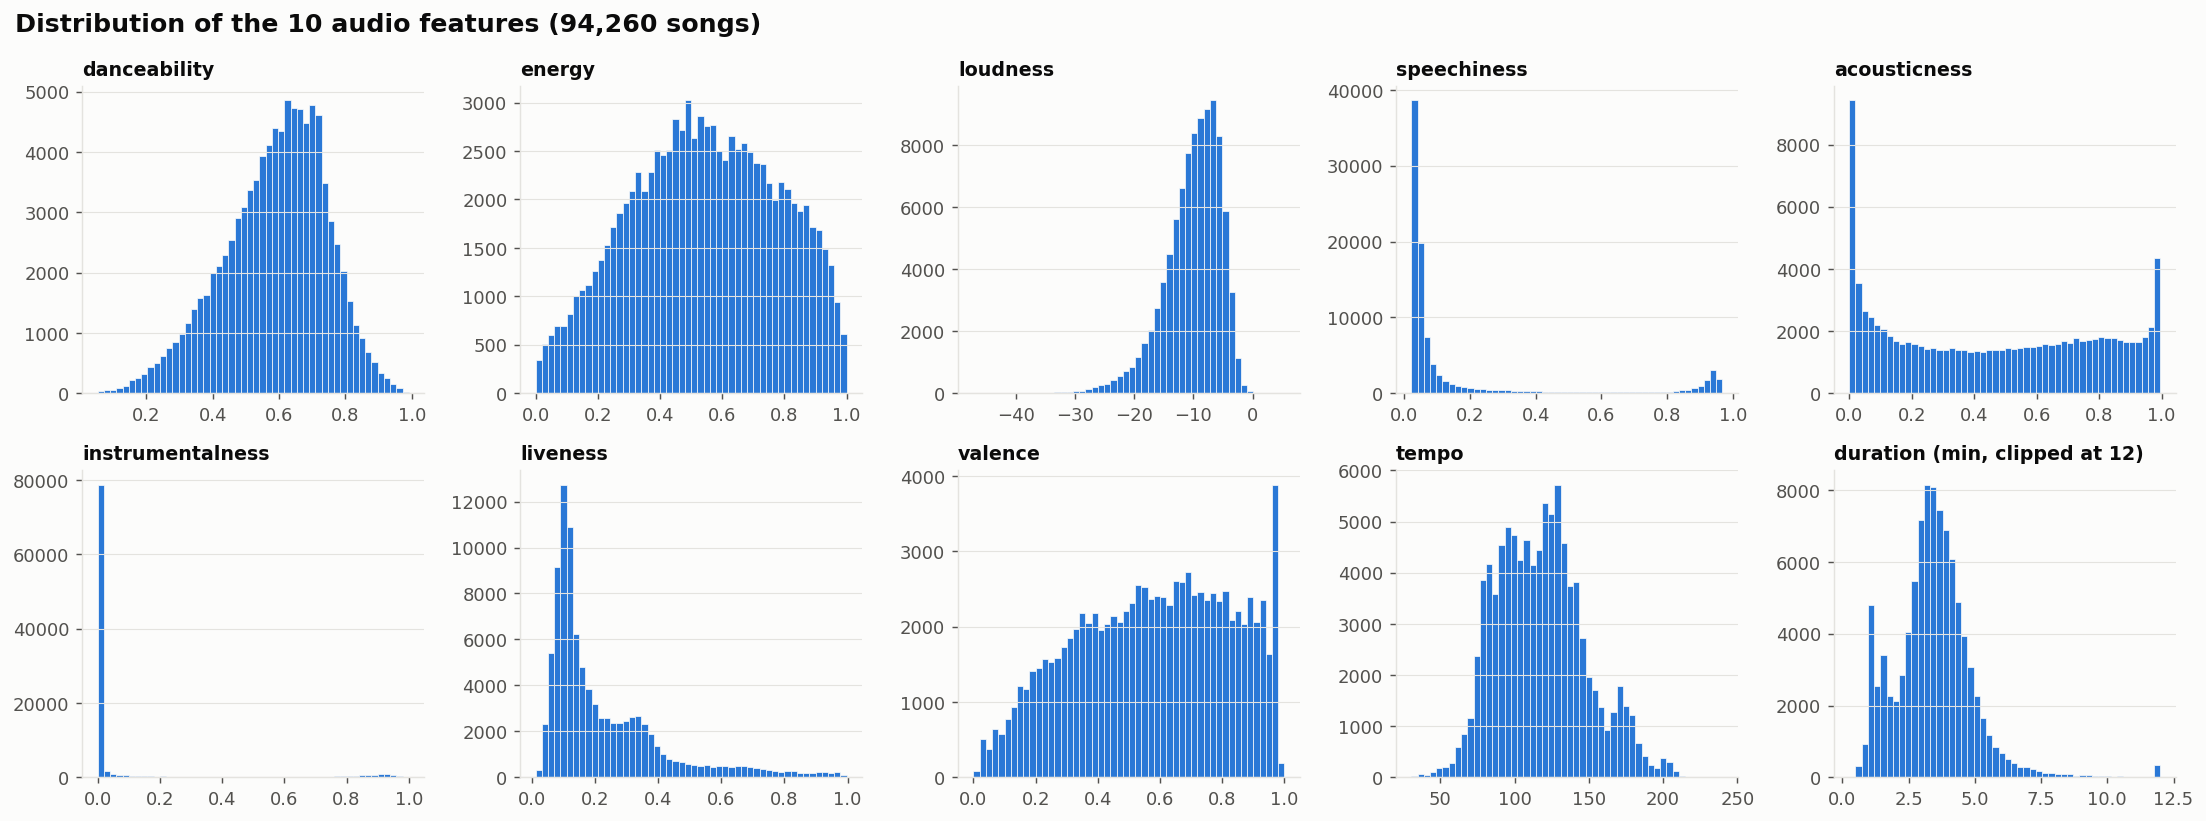

In [8]:
viz.feature_distributions(df); show("01_feature_distributions.png")

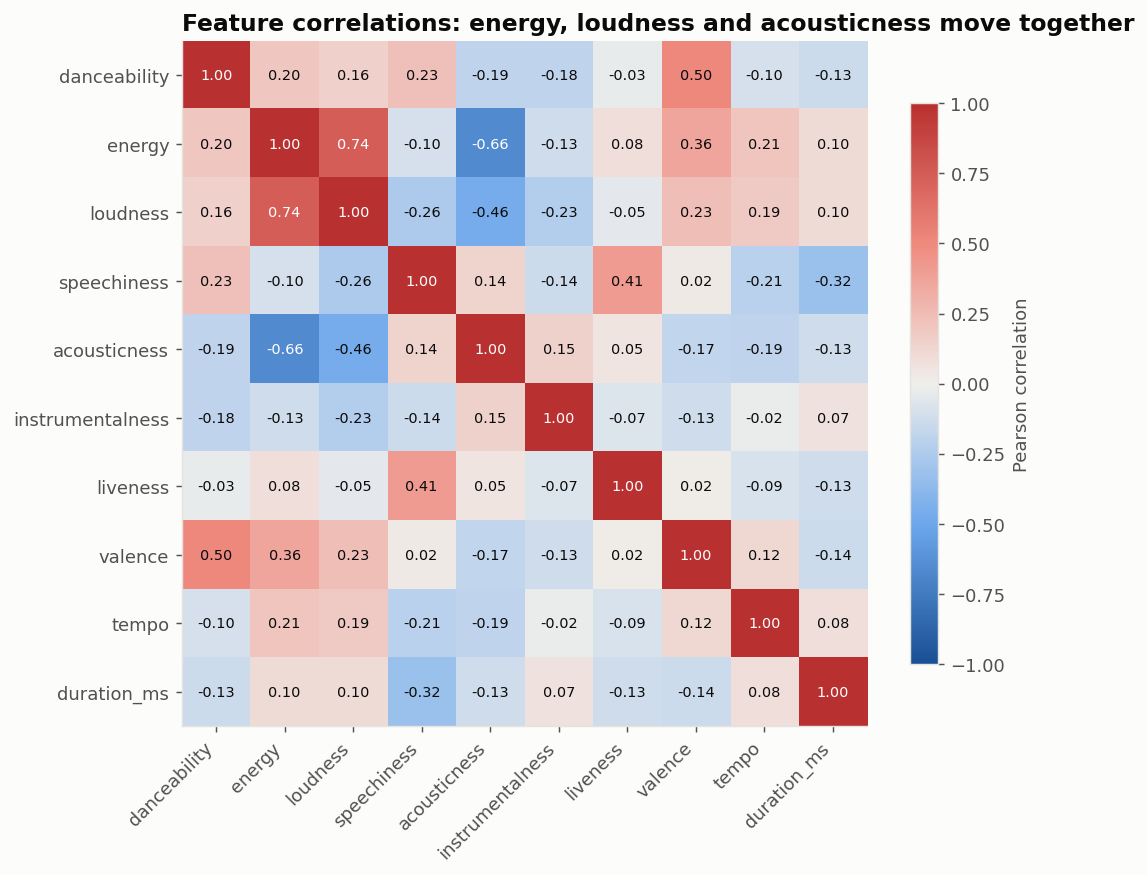

In [9]:
viz.correlation_heatmap(df); show("02_correlation_heatmap.png")

Energy, loudness and (negatively) acousticness are strongly correlated: together they form
an "intensity" axis. Speechiness and instrumentalness are almost independent of the rest,
so they should drive their own clusters.

## 3. Feature selection and normalisation

In [10]:
X = dp.feature_matrix(df)          # the 10 audio features, log(duration)
Xs, scaler = dp.scale(X)           # StandardScaler: mean 0, sd 1
print(FEATURES)
pd.DataFrame(Xs, columns=FEATURES).describe().T[["mean", "std"]].round(3)

['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']


,mean,std
danceability,-0.0,1.0
energy,-0.0,1.0
loudness,-0.0,1.0
speechiness,-0.0,1.0
acousticness,0.0,1.0
instrumentalness,0.0,1.0
liveness,-0.0,1.0
valence,-0.0,1.0
tempo,-0.0,1.0
duration_ms,-0.0,1.0


K-Means uses Euclidean distance, so without scaling `tempo` (about 120) and `loudness`
(about -10) would swamp the 0-1 features. `duration_ms` is log-transformed first so a few
very long tracks do not dominate.

## 4. Choosing the number of clusters

In [11]:
k_df = cl.evaluate_k_range(Xs)
k_df.round(4)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
0,2,757812.7742,0.2103,1.9299,22984.2407,42.3159,57.6841
1,3,621492.4843,0.2445,1.5507,24349.9782,13.4808,54.3009
2,4,557026.7556,0.2320,1.5089,21747.9705,7.9907,48.0925
3,5,513009.5000,0.1890,1.6680,19732.1258,7.6321,31.5256
4,6,485530.7397,0.1648,1.6904,17745.8495,7.4411,25.3501
5,7,460096.8063,0.1693,1.6071,16473.8633,4.8080,24.4409
6,8,438916.3964,0.1671,1.5333,15451.4327,4.6075,21.5319
7,9,415923.6984,0.1731,1.5158,14918.5615,4.2340,21.1818
8,10,402649.1492,0.1650,1.5487,14043.2361,4.1916,19.0866


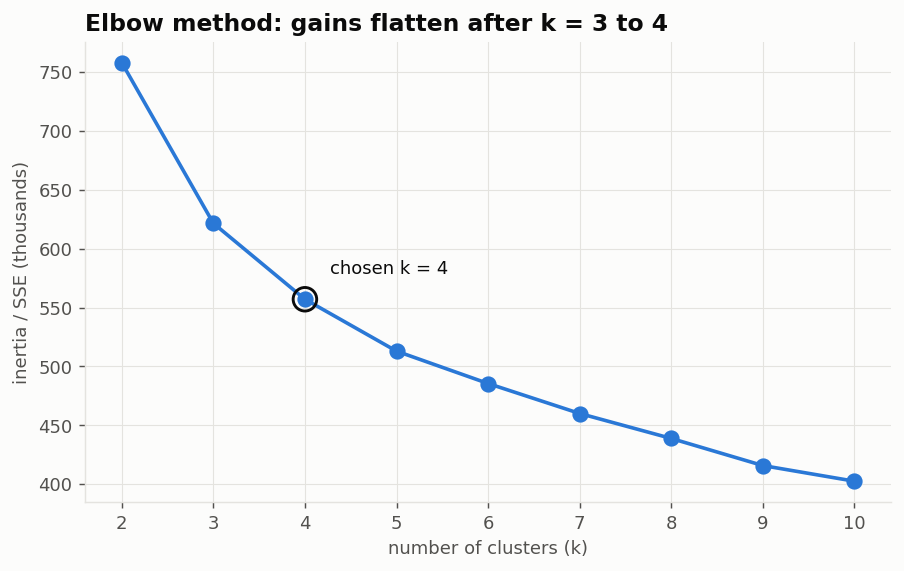

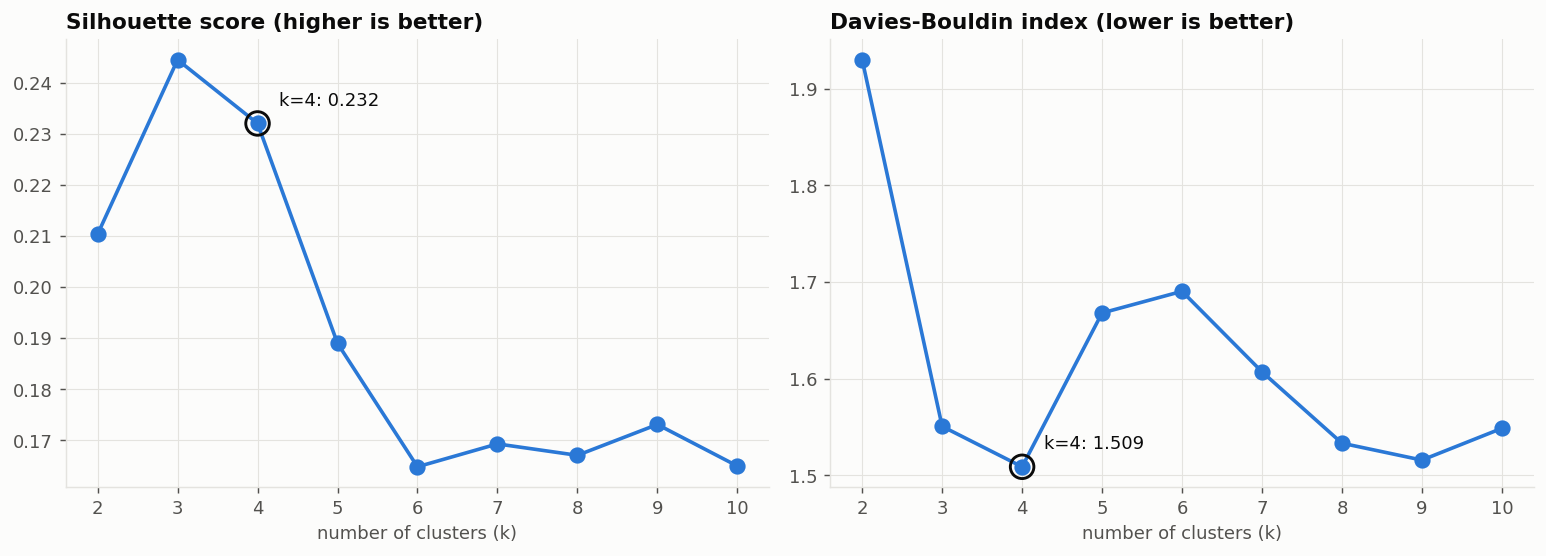

In [12]:
viz.elbow_plot(k_df, K_FINAL); show("03_elbow_method.png")
viz.k_scores_plot(k_df, K_FINAL); show("04_silhouette_davies_bouldin.png")

**Decision: k = 4.**
- The elbow bends at k = 3 to 4; after that each extra cluster removes less SSE.
- k = 3 has the highest silhouette, but **k = 4 is within about 0.013** and has the **lowest
  Davies-Bouldin index** of all k tried.
- k = 4 separates *instrumental / soundtrack* music from vocal *mellow* songs. This is a split
  that matters for playlists (focus/study vs chill), which k = 3 merges.
- Silhouette values around 0.2 to 0.25 are normal for audio features: songs vary
  continuously rather than forming well-separated islands.

## 5. Final K-Means model

In [13]:
km = cl.fit_kmeans(Xs, K_FINAL)
df["cluster"] = km.labels_
prof = cl.profile(df)
names = {c: cl.name_cluster(prof.loc[c]) for c in prof.index}
df["cluster_name"] = df["cluster"].map(names)
prof.index = prof.index.map(names)
names

{0: 'Instrumental & Soundtrack',
 1: 'Mellow Acoustic',
 2: 'Upbeat & Energetic',
 3: 'Spoken Word & Audio Drama'}

In [14]:
prof[FEATURES[:-1] + ["duration_min", "songs", "share_pct", "avg_popularity"]].round(3)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_min,songs,share_pct,avg_popularity
cluster,,,,,,,,,,,,,
Instrumental & Soundtrack,0.488,0.413,-14.065,0.060,0.653,0.812,0.187,0.454,114.744,3.767,7532,7.991,17.099
Mellow Acoustic,0.505,0.344,-12.114,0.063,0.698,0.017,0.185,0.427,113.755,3.788,28777,30.529,22.422
Upbeat & Energetic,0.635,0.709,-7.410,0.076,0.241,0.022,0.201,0.686,125.245,3.772,45332,48.093,29.309
Spoken Word & Audio Drama,0.664,0.467,-13.295,0.820,0.582,0.001,0.427,0.585,100.646,1.516,12619,13.387,28.296


## 6. Comparison with DBSCAN and hierarchical clustering

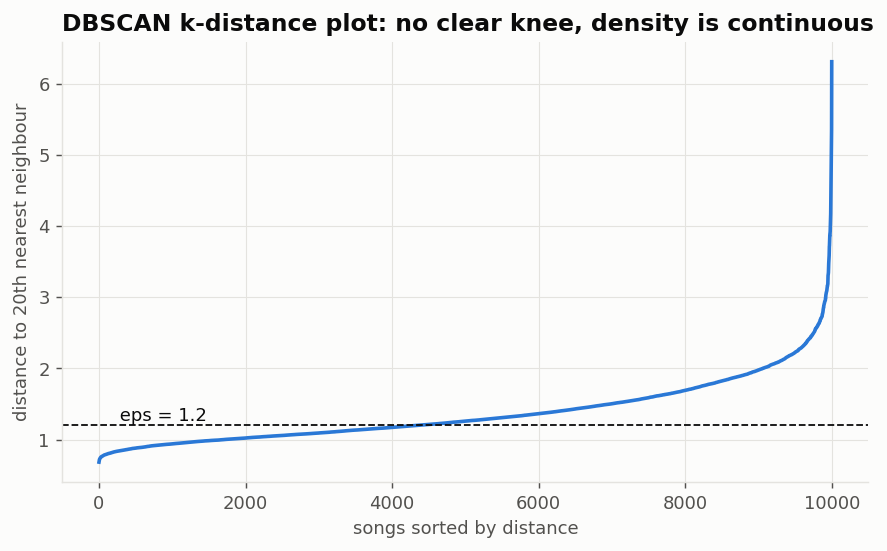

,eps,min_samples,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
0,0.8,20,4,92.95,0.458,1.031,335.084,2.128,80.709
1,1.0,20,2,57.56,0.387,0.771,384.945,2.615,97.385
2,1.2,20,2,32.11,0.384,0.939,1793.051,8.705,91.295
3,1.5,20,3,14.29,0.209,0.953,310.255,0.327,97.433
4,1.8,20,1,4.35,NaN,NaN,NaN,NaN,NaN


In [15]:
idx = np.random.RandomState(7).choice(len(Xs), 10_000, replace=False)
kd = cl.k_distance(Xs[idx], DBSCAN_MIN_SAMPLES)
viz.k_distance_plot(kd, DBSCAN_EPS, DBSCAN_MIN_SAMPLES); show("12_dbscan_k_distance.png")
pd.read_csv(REPORTS / "dbscan_eps_grid.csv").round(3)

The k-distance curve rises smoothly with no sharp knee, so song density changes
gradually. Small eps values label most songs as noise; larger values merge almost everything
into one cluster. DBSCAN cannot find several meaningful dense groups here.

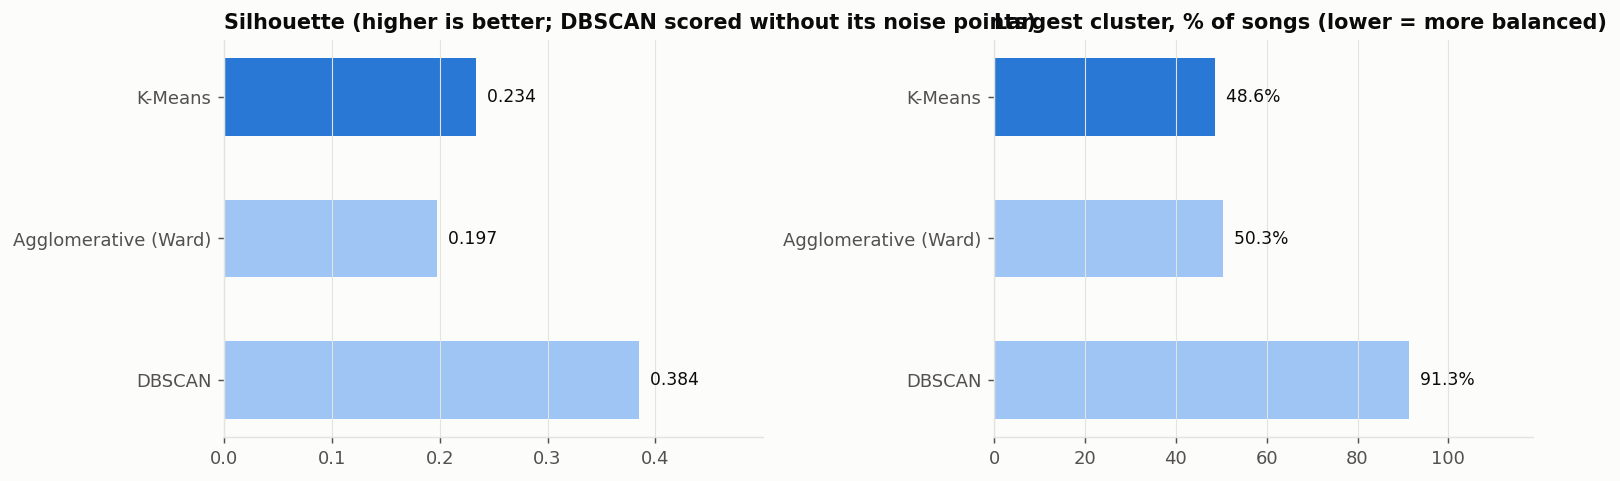

,algorithm,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
0,K-Means,4,0.00,0.234,1.504,2306.210,7.720,48.630
1,Agglomerative (Ward),4,0.00,0.197,1.661,1981.278,9.240,50.310
2,DBSCAN,2,32.11,0.384,0.939,1793.051,8.705,91.295


In [16]:
cmp_df, _ = cl.compare_algorithms(Xs, km, K_FINAL, DBSCAN_EPS, DBSCAN_MIN_SAMPLES)
viz.algorithm_comparison(cmp_df); show("13_algorithm_comparison.png")
cmp_df.round(3)

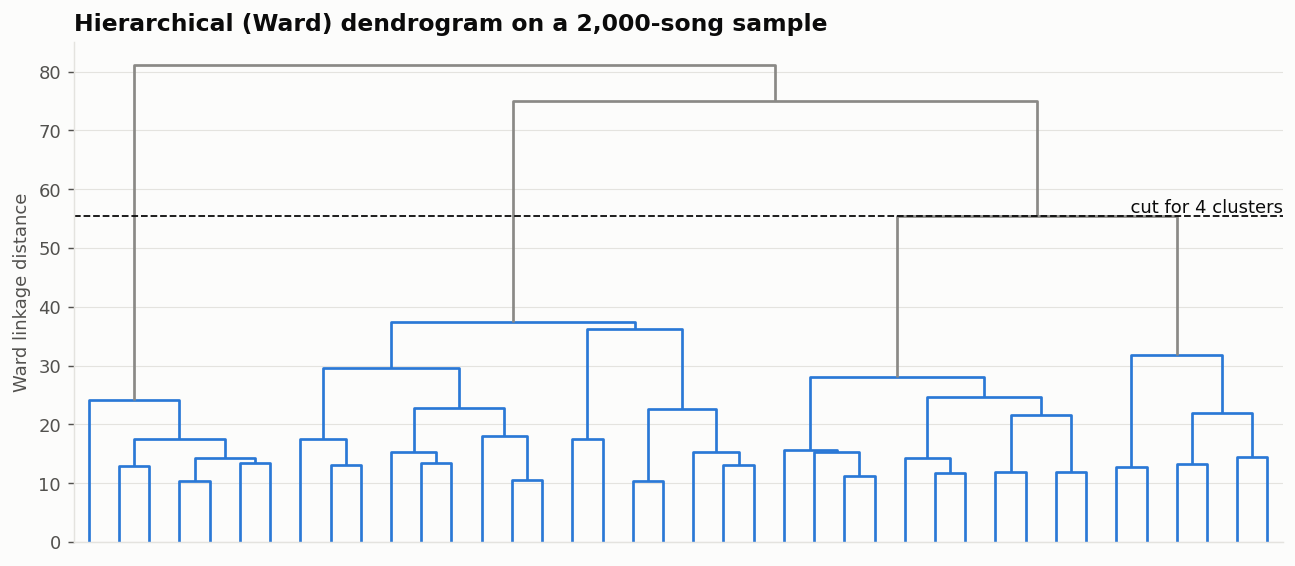

In [17]:
didx = np.random.RandomState(3).choice(len(Xs), DENDRO_SAMPLE, replace=False)
viz.dendrogram_plot(Xs[didx], K_FINAL); show("11_dendrogram.png")

- **K-Means** beats Agglomerative (Ward) on both silhouette and Davies-Bouldin, with similar
  balance, and it scales to the full 94k songs (Ward needs O(n²) memory).
- **DBSCAN's** higher silhouette is computed only on the songs it does not call noise (about
  a third are noise), and over 90% of the rest fall in one cluster. It is not a usable
  segmentation of this catalogue.
- The dendrogram shows four well-separated branches at the cut, which supports k = 4.

**K-Means (k = 4) is the final model.**

## 7. Visualising the clusters

explained variance: [0.277 0.21  0.115]


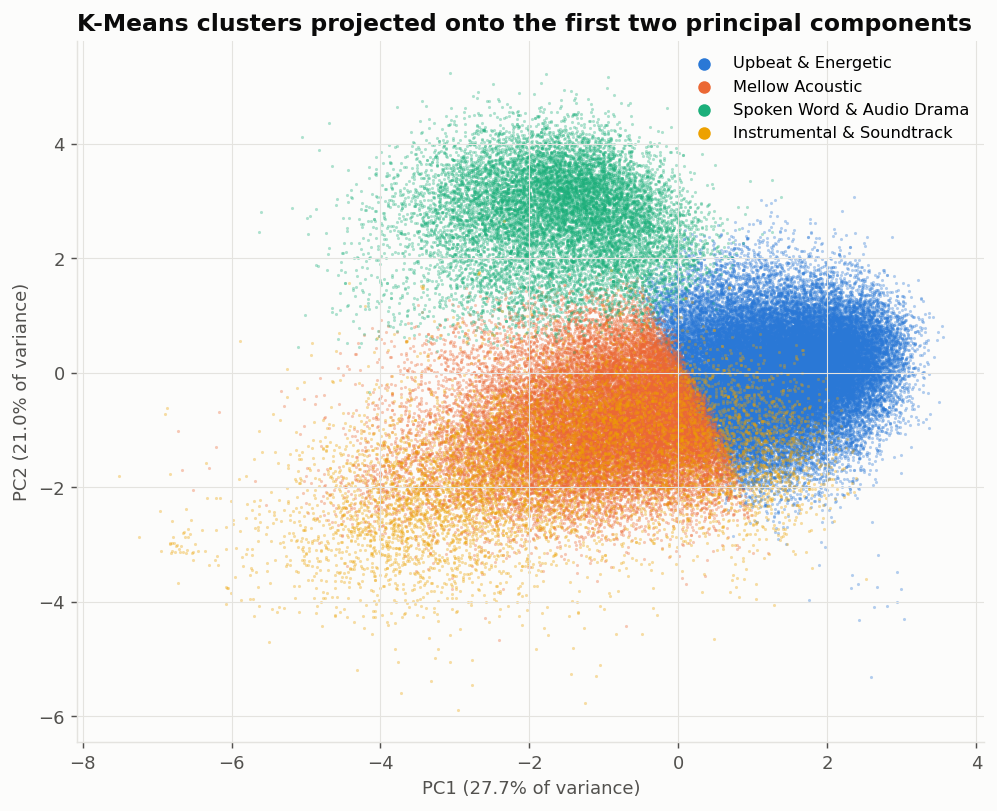

In [18]:
pca = PCA(n_components=3, random_state=RANDOM_STATE).fit(Xs)
pcs = pca.transform(Xs)
print("explained variance:", pca.explained_variance_ratio_.round(3))
viz.pca_scatter(pcs, df["cluster_name"].values, pca.explained_variance_ratio_)
show("05_pca_clusters.png")

In [19]:
pd.DataFrame(pca.components_[:2], columns=FEATURES, index=["PC1", "PC2"]).round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
PC1,0.18,0.52,0.49,-0.22,-0.45,-0.15,-0.09,0.27,0.22,0.23
PC2,0.41,0.13,0.02,0.52,-0.04,-0.24,0.34,0.33,-0.16,-0.48


PC1 is the intensity axis (energy, loudness, low acousticness). PC2 is driven by speechiness, danceability and
liveness (spoken word) against long duration and instrumentalness. The four clusters occupy different regions.

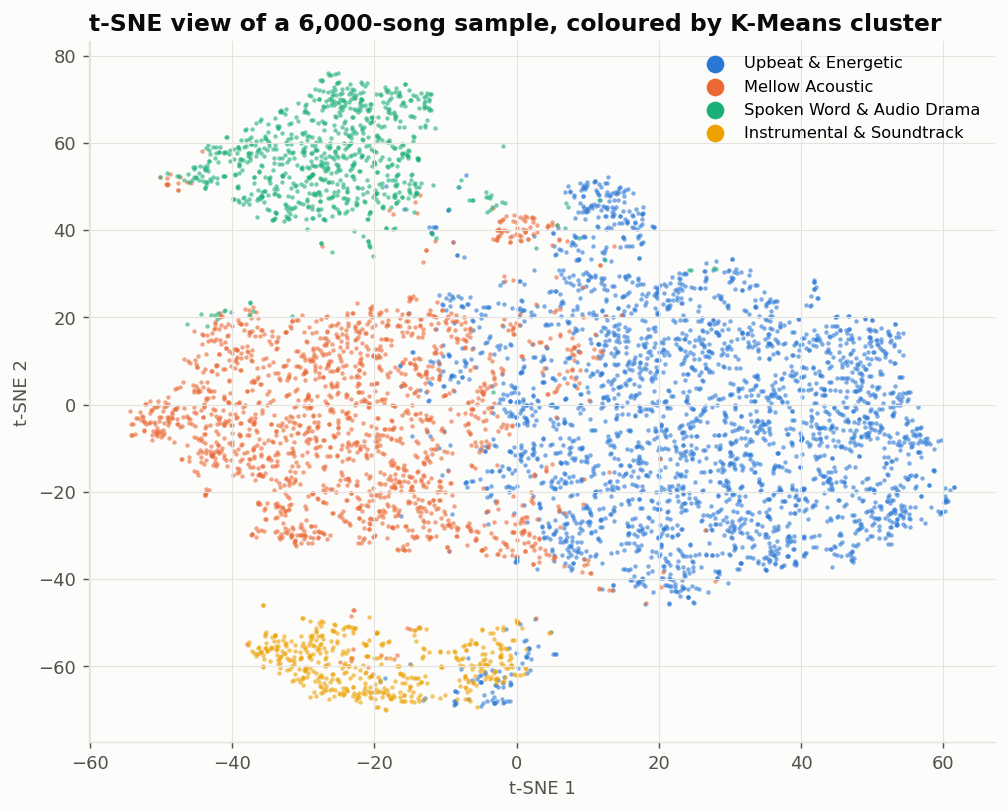

In [20]:
tidx = np.random.RandomState(11).choice(len(Xs), TSNE_SAMPLE, replace=False)
emb = TSNE(n_components=2, perplexity=40, init="pca",
           random_state=RANDOM_STATE).fit_transform(Xs[tidx])
viz.tsne_scatter(emb, df["cluster_name"].values[tidx]); show("06_tsne_clusters.png")

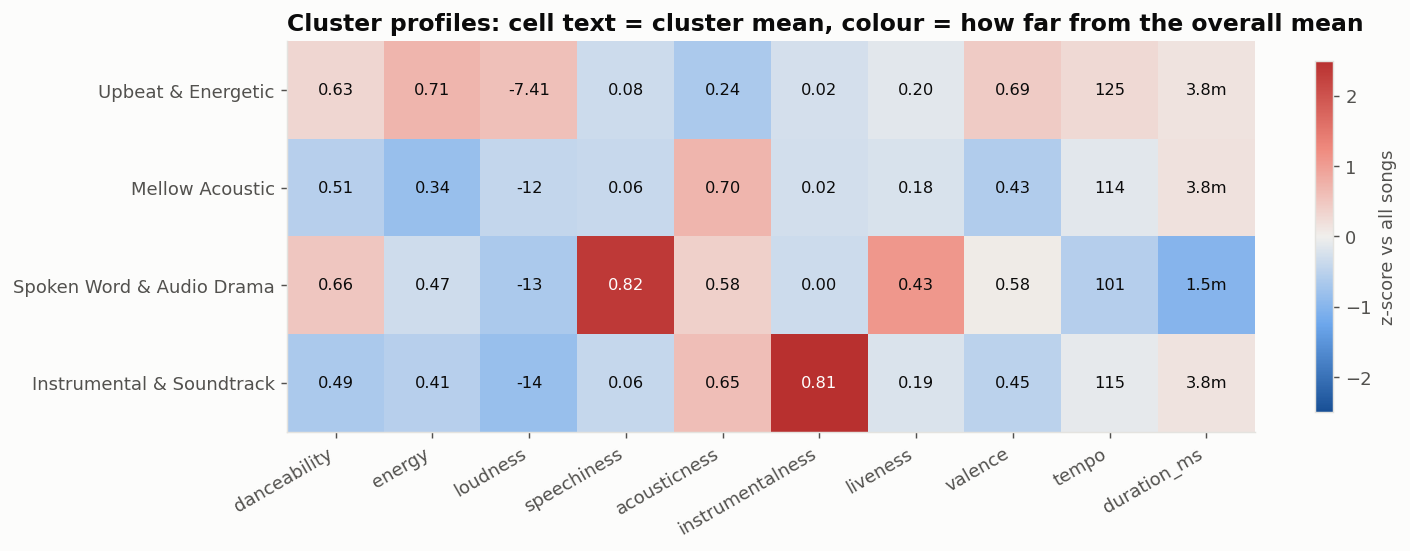

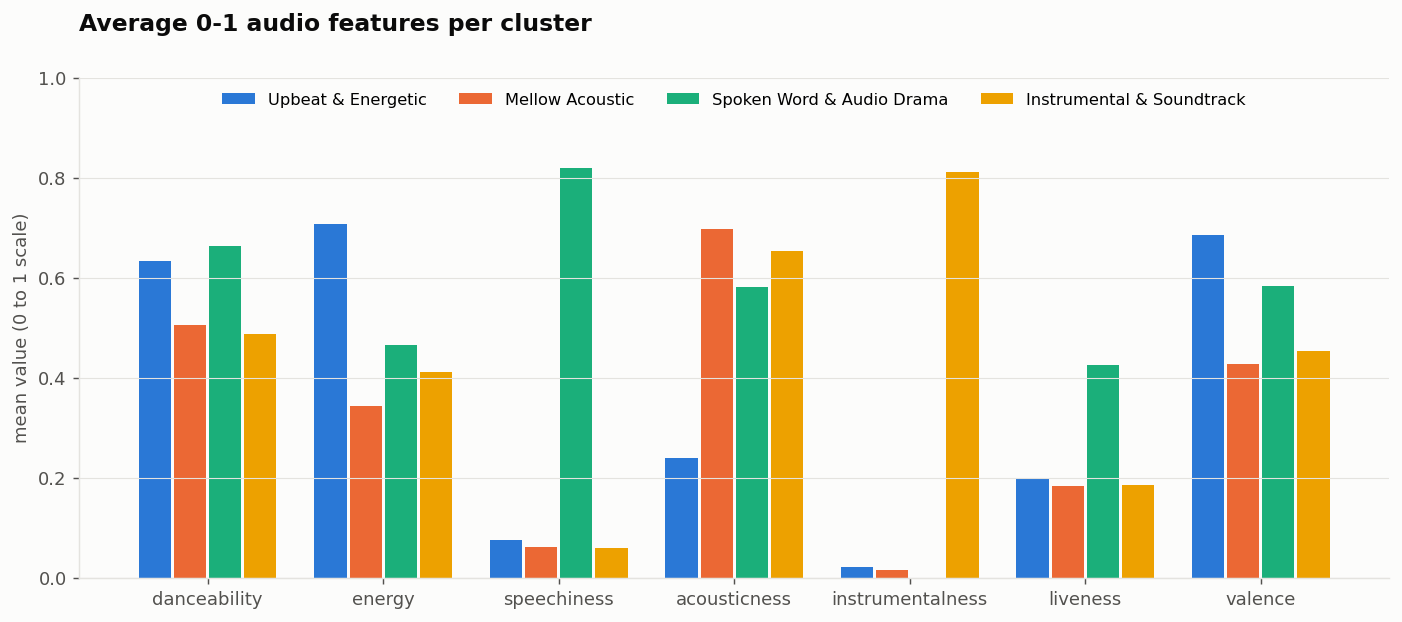

In [21]:
viz.profile_heatmap(prof, df); show("07_cluster_profile_heatmap.png")
viz.feature_means_bars(prof); show("08_feature_means_by_cluster.png")

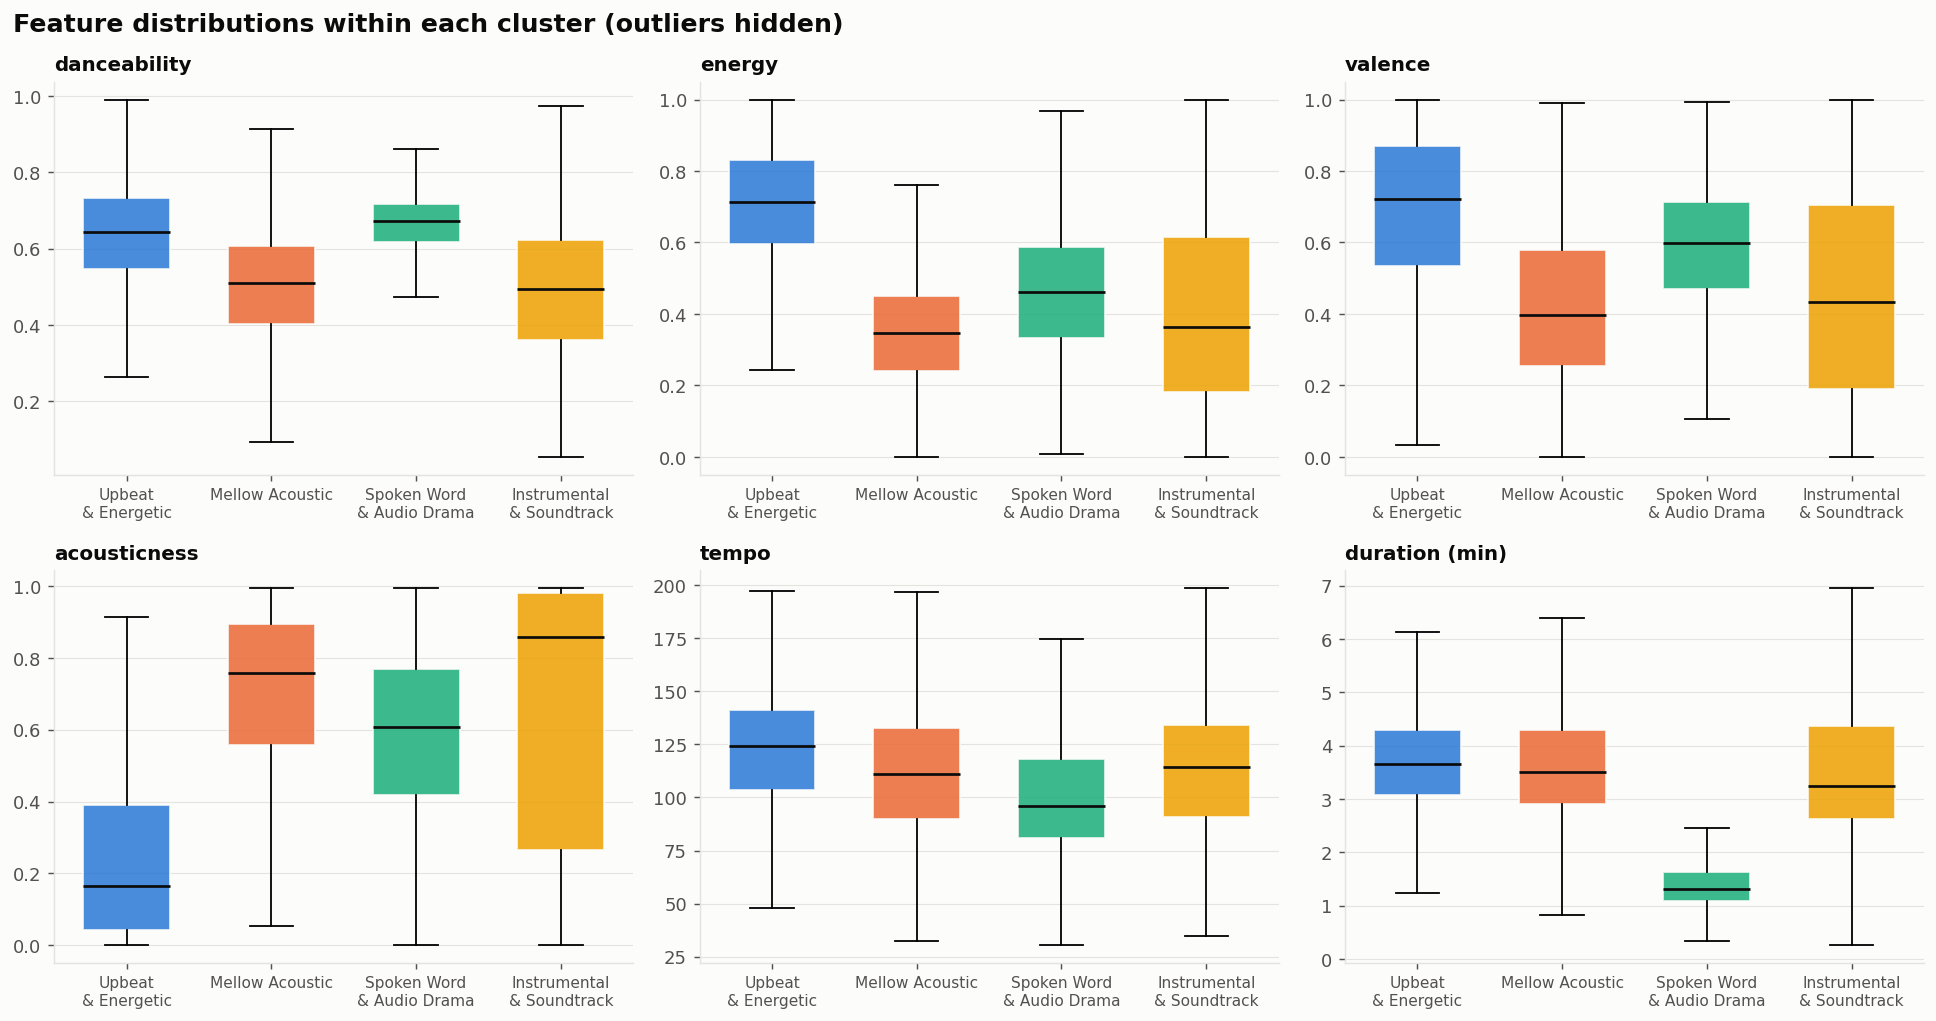

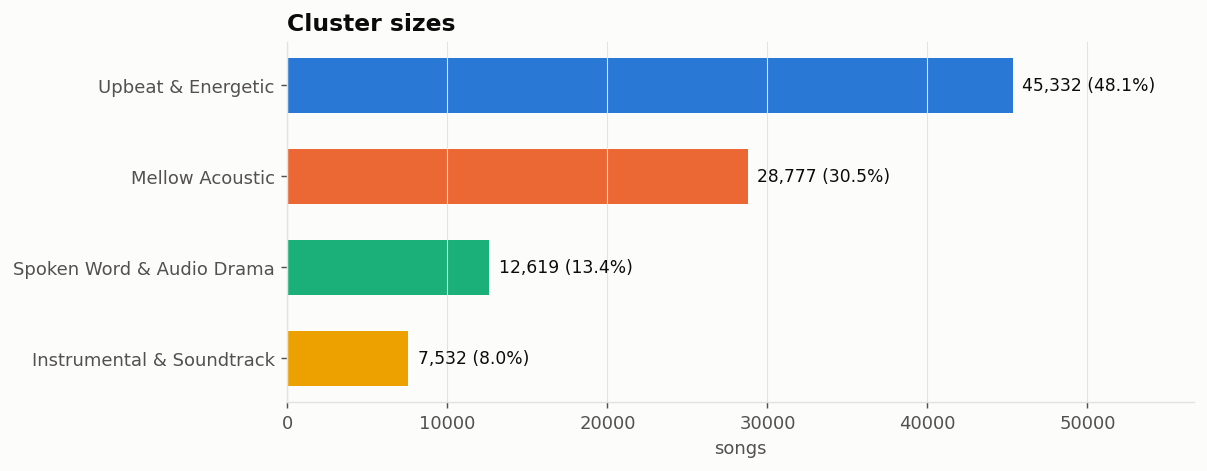

In [22]:
viz.feature_boxplots(df); show("09_feature_boxplots_by_cluster.png")
viz.cluster_sizes(prof); show("10_cluster_sizes.png")

## 8. Interpretation

In [23]:
for n in viz.CLUSTER_ORDER:
    print(f"{n}  ({prof.loc[n, 'songs']:,.0f} songs, {prof.loc[n, 'share_pct']:.1f}%)")
    print("   ", cl.CLUSTER_DESCRIPTIONS[n], "\n")

Upbeat & Energetic  (45,332 songs, 48.1%)
    High energy, loud, danceable and positive (high valence): modern pop, J-pop, dance and rock. Suited to party, workout and driving playlists. 

Mellow Acoustic  (28,777 songs, 30.5%)
    Low energy, quiet and very acoustic with vocals: vintage and classic pop, ballads and folk from many countries. Suited to chill, relaxing and nostalgia playlists. 

Spoken Word & Audio Drama  (12,619 songs, 13.4%)
    Very high speechiness and short duration: audio-book and radio-play chapters (German Hoerspiel dominates), plus comedy and spoken tracks. Keep out of music playlists; recommend within itself. 

Instrumental & Soundtrack  (7,532 songs, 8.0%)
    Very high instrumentalness, quiet and acoustic: film scores, classical, ambient and lo-fi pieces. Suited to focus, study and background playlists. 



| Cluster | Defining features | Use |
|---|---|---|
| **Upbeat & Energetic** (48%) | energy 0.71, loudness -7.4 dB, valence 0.69, low acousticness 0.24, fastest tempo (125 BPM) | party, workout, driving |
| **Mellow Acoustic** (31%) | lowest energy 0.34, acousticness 0.70, low valence 0.43, vocals (instrumentalness 0.02) | chill, relax, nostalgia |
| **Spoken Word & Audio Drama** (13%) | speechiness 0.82, liveness 0.43, short tracks (1.5 min) | audiobooks; keep out of music mixes |
| **Instrumental & Soundtrack** (8%) | instrumentalness 0.81, quietest (-14 dB), acoustic 0.65 | focus, study, sleep |

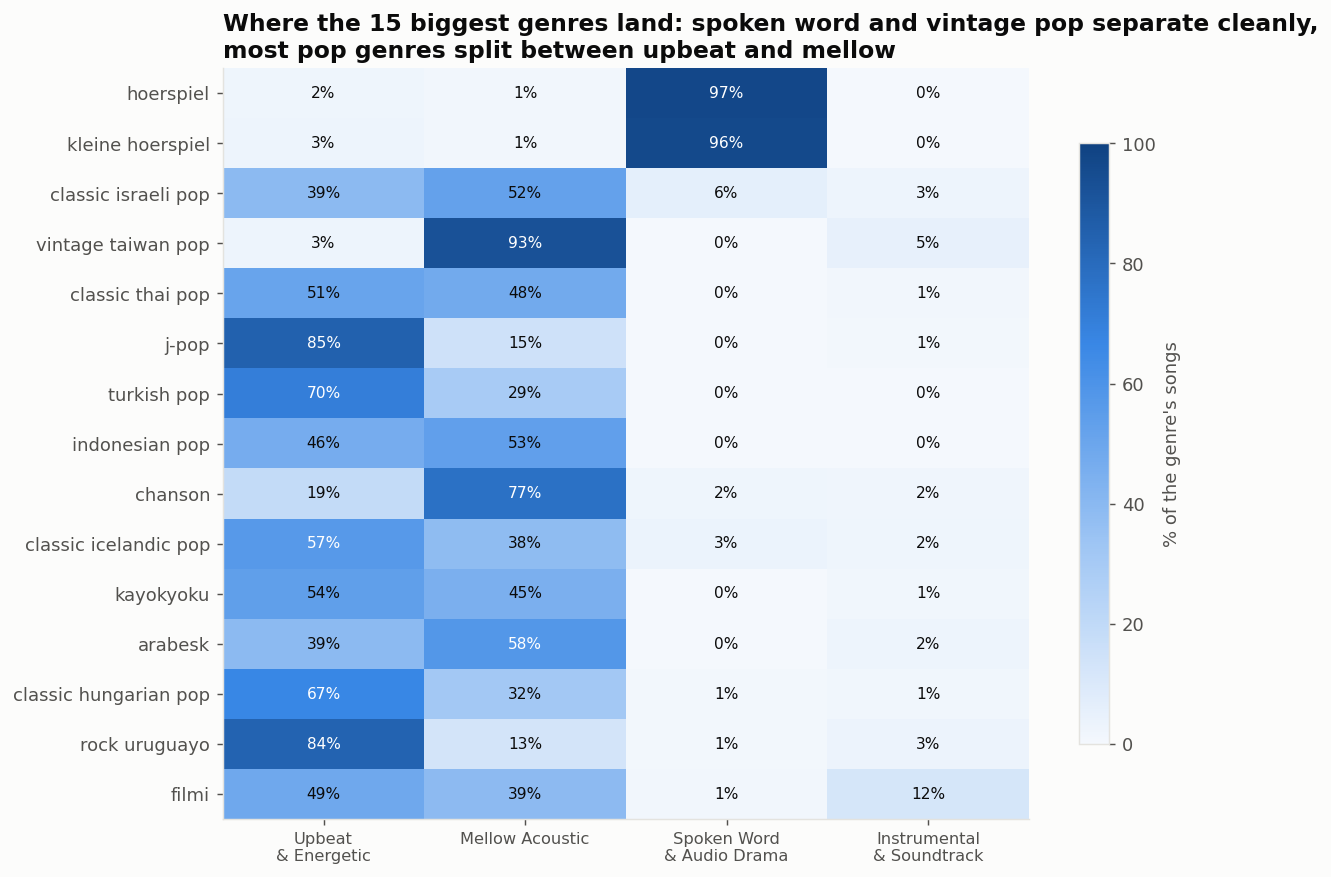

In [24]:
top15 = df["genre"].value_counts().drop("unknown", errors="ignore").head(15).index
gx = (pd.crosstab(df.loc[df.genre.isin(top15), "genre"],
                  df.loc[df.genre.isin(top15), "cluster_name"], normalize="index") * 100).loc[top15]
viz.genre_heatmap(gx); show("14_genre_by_cluster.png")

**Genre check (made after clustering, genre was never an input):**
- 97% of *hoerspiel* songs land in Spoken Word, and 93% of *vintage taiwan pop* in Mellow Acoustic.
- Modern genres like *j-pop* (85%) and *rock uruguayo* (84%) land mostly in Upbeat & Energetic.
- Many pop genres split between Upbeat and Mellow. This is expected: a genre contains both
  ballads and dance tracks, and these clusters capture **mood and sound** rather than genre labels.

In [25]:
cl.top_tracks(df, 5)

,cluster_name,name_song,name_artists,genre,popularity_songs,energy,acousticness,instrumentalness,speechiness
0,Instrumental & Soundtrack,ROLLIN N CONTROLLIN FREESTYLE,DUSTY LOCANE,new york drill,83,0.514,0.09750,0.497000,0.3280
1,Instrumental & Soundtrack,YKWIM?,Yot Club,bedroom pop,79,0.537,0.93500,0.893000,0.0268
2,Instrumental & Soundtrack,Jealous,Eyedress,noise pop,78,0.910,0.00498,0.859000,0.0462
3,Instrumental & Soundtrack,Buttercup,Jack Stauber,pittsburgh indie,78,0.373,0.72300,0.810000,0.0384
4,Instrumental & Soundtrack,Show Me How,Men I Trust,indie pop,75,0.267,0.67400,0.534000,0.0415
5,Mellow Acoustic,What You Know Bout Love,Pop Smoke,brooklyn drill,91,0.548,0.65000,0.000002,0.3530
6,Mellow Acoustic,Arcade,Duncan Laurence,dutch pop,89,0.329,0.81800,0.001090,0.0441
7,Mellow Acoustic,Put Your Records On,Ritt Momney,bedroom pop,87,0.491,0.05630,0.000890,0.0538
8,Mellow Acoustic,Hold On,Chord Overstreet,acoustic pop,83,0.443,0.46900,0.000000,0.0526
9,Mellow Acoustic,Party Girl,StaySolidRocky,melodic rap,81,0.431,0.74900,0.000000,0.0622


In [26]:
cl.typical_tracks(df, Xs, km, 5)

,cluster_name,name_song,name_artists,genre,dist_to_centroid
0,Instrumental & Soundtrack,Bolero,Fivos Delivorias,entehno,0.707157
1,Instrumental & Soundtrack,Five,Bill Evans,adult standards,0.807096
2,Instrumental & Soundtrack,I Love You,Bill Evans,adult standards,0.867096
3,Instrumental & Soundtrack,Porque Así Me Gusta a Mí,Canciones Para No Dormir La Siesta,musica de fondo,0.883015
4,Instrumental & Soundtrack,Bedir,Yedi Karanfil,turkish folk,0.990090
5,Mellow Acoustic,นกนางนวล,Chatree,classic thai pop,0.442232
6,Mellow Acoustic,Lainaat mulle lantin kait,Pärre Förars,classic iskelma,0.489927
7,Mellow Acoustic,ליל אמש,Meadows End,classic israeli pop,0.566279
8,Mellow Acoustic,หรูเหอ - (如何 Skyline Ost. แปลรักฉันด้วยใจเธอ),PP,thai idol,0.575972
9,Mellow Acoustic,一人一半,Wu Jia Hui,malaysian mandopop,0.580767


## 9. Export

In [27]:
import json
print(OUTPUT_CSV.relative_to(ROOT), "exists:", OUTPUT_CSV.exists())
out = pd.read_csv(OUTPUT_CSV)
print(out.shape)
out[["name_song", "name_artists", "genre", "cluster", "cluster_name"]].sample(8, random_state=0)

outputs\amazon_music_clustered.csv exists: True


(94260, 27)


,name_song,name_artists,genre,cluster,cluster_name
45681,Carta de un niño mal logrado (Gallino),Avelino Montenegro,folklore panameno,1,Mellow Acoustic
41258,Song of the Blues,Isham Jones,tin pan alley,1,Mellow Acoustic
61326,Hofeher Jaguar,United,classic hungarian pop,2,Upbeat & Energetic
66307,Les pensées,The Architect,electro dub,2,Upbeat & Energetic
30217,Daylight,ARASHI,j-pop,2,Upbeat & Energetic
43062,Vi Vil Værne Om Jorden,Vesterbro Ungdomsgård,bornesange,1,Mellow Acoustic
17858,079 - Im Bann des Voodoo - Teil 30,Die drei ???,hoerspiel,3,Spoken Word & Audio Drama
37479,אהבה בת 20,Yossi Banai,classic israeli pop,1,Mellow Acoustic


In [28]:
json.loads((REPORTS / "summary.json").read_text())["kmeans_full"]

{'silhouette_sample_20k': 0.232,
 'davies_bouldin': 1.5089,
 'calinski_harabasz': 21748.0,
 'inertia': 557026.8}

The full labelled dataset (`outputs/amazon_music_clustered.csv`), the CSV tables in `reports/`,
the figures and the trained model (`models/kmeans_model.joblib`) are produced by
`python -m src.run_pipeline` (run by `run_all.bat` before this notebook).

## 10. Conclusions and recommendations
1. **Four sound-based segments** cover the catalogue: Upbeat & Energetic (48%), Mellow Acoustic
   (31%), Spoken Word & Audio Drama (13%) and Instrumental & Soundtrack (8%).
2. **Playlist curation:** use each cluster as the candidate pool for mood playlists, then rank
   by popularity or distance to the centroid.
3. **Song discovery:** recommend the nearest songs *within* the same cluster (see the
   Streamlit app's "Find similar songs" page).
4. **Separate spoken content:** 13% of tracks are audio drama or spoken word. Exclude them from
   music recommendations and give them their own shelf.
5. **Artist analysis:** an artist can see which cluster their track falls into and which
   popular songs it competes with.
6. **Limitations:** silhouette about 0.23 shows the clusters overlap at their edges (songs vary
   continuously). Genre is one label per artist, so the genre check is approximate. Next steps:
   use sub-clusters inside the big Upbeat group, or add user listening data.